# Estudo sobre Acidentes e Incidentes Aérios em solo Brasileiro

por Ítalo dos Santos Araujo Chaves

![Imagem de um avião](./images/aeronave-gol-25-anos-jpg)

## Breve Introdução
A aviação é o modal de transporte considerado o mais seguro, fica atrás apenas do elevador.  Cobrindo longas viagens em um curto espaço de tempo, tais aeronaves proveram diversas vantagens para o mundo, tanto comercial quanto a lazer. Infelizmente, como todo meio de transporte, as aeronaves possuem sua conta de tragédias.

## Sobre este estudo
Nesta apresentação, eu estarei utilizando dados abertos disponibilizados pela CENIPA - Centro de Investigação e Prevenção de Acidentes aeronáuticos. Tais arquivos conterão informações sobre ocorrências envolvendo aeronaves nos últimos 10 anos. Você pode acessar dados mais atualizados visitando a página oficial de Dados Abertos Brasileiros, mas, caso deseje, poderá estar realizando o download dos datasets utilizados aqui através dos links de download abaixo.

Para este estudo, utilizarei de dois datasets da CENIPA:

**Ocorrencia.csv**: possui os dados sobre cada ocorrência registrada nos últimos 10 anos. Código da ocorrência, Data, Motivo da Ocorrência e Localização serão encontrados nesse conjunto de dados.

**Tipo_Ocorrencia.csv**: lista os tipos de ocorrências documentas pelo SIPAER.

**Aeronave.csv**: informações agrupadas sobre as aeronaves envolvidas nas ocorrências registradas no arquivo ocorrencia.csv. Aqui serão encontrados dados como: Modelo da Aeronave, Tipo de Aeronave, Fabricante, Quantidade de Fatalidades, dentre outras.

**Fator_Contribuinte.csv**: Detalhe os fatores contribuintes para ocorrência com os seguintes campos: Código de ocorrencia, Nome do fator, aspecto do fator, Fator condicionante e area. (Futuramente)

**Recomendacao.csv**: lista melhorias de segurança / procedimentos e ações para evitar novos acidentes/incidentes pelos fatores já conhecidos. (Futuramente)


## Perguntas a serem respondidas
Dentre outros insights gerados através deste estudo, quero responder as seguintes perguntas:

Quais são as maiores causas de ocorrências e, eventualmente, queda de aviões?

Como tem sido a progressão desses casos nos últimos anos? Tiveram menos ocorrências ou mais?

Quais os estados que mais possuem ocorrências registradas?

Qual tipo de aeronave possui mais problemas? Aviões, jatos, planadores?

Quais as fabricantes com maior número de defeitos registrados?

Será que durante o pouso é mais comum ter problemas do que durante a decolagem? Ou durante a viagem em si é mais frequente surgir defeitos?

Viagens comerciais regulares tendem a ter mais problemas do que voos fretados?

Quantos incidentes com fatalidades (morte de passageiros e tripulação) temos registro nos últimos 10 anos?



### Importando Bibliotecas

In [197]:
from docutils.nodes import fully_normalize_name
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
import random

### Leitura Conjunto de dados

In [198]:
ocorrencia = pd.read_csv('./dataset/ocorrencia.csv', encoding='latin1', sep=';')
tipo_ocorrencia = pd.read_csv('./dataset/tipo_ocorrencia.csv', encoding='latin1', sep=';')
aeronave = pd.read_csv('./dataset/aeronave.csv', encoding='latin1', sep=';')
# fator_contribuinte = pd.read_csv('./dataset/fator_contribuinte.csv', encoding='latin1', sep=';')
# recomendacao = pd.read_csv('./dataset/recomendacao.csv', encoding='latin1', sep=';')

## Limpeza de Dados

O primeiro processo deste estudo será realizar a limpeza e tratativa dos dados. Vamos inicialmente verificar como a tabela do arquivo "ocorrencia.csv" é apresentada.

In [199]:
ocorrencia.head(5)


,codigo_ocorrencia,codigo_ocorrencia1,codigo_ocorrencia2,codigo_ocorrencia3,codigo_ocorrencia4,ocorrencia_classificacao,ocorrencia_latitude,ocorrencia_longitude,ocorrencia_cidade,ocorrencia_uf,...,ocorrencia_dia,ocorrencia_hora,investigacao_aeronave_liberada,investigacao_status,divulgacao_relatorio_numero,divulgacao_relatorio_publicado,divulgacao_dia_publicacao,total_recomendacoes,total_aeronaves_envolvidas,ocorrencia_saida_pista
0,88808,88808,88808,88808,88808,INCIDENTE,-23.43555555555,-46.47305555555,GUARULHOS,SP,...,19/04/2026,04:00:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
1,88804,88804,88804,88804,88804,INCIDENTE,-23.43555555555,-46.47305555555,GUARULHOS,SP,...,23/04/2026,15:00:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
2,88794,88794,88794,88794,88794,INCIDENTE,-22.81,-43.25055555555,RIO DE JANEIRO,RJ,...,28/04/2026,18:36:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
3,88783,88783,88783,88783,88783,INCIDENTE,-22.81,-43.25055555555,RIO DE JANEIRO,RJ,...,30/04/2026,19:30:00,SIM,FINALIZADA,***,NÃO,NaN,0,1,NÃO
4,88769,88769,88769,88769,88769,INCIDENTE GRAVE,-12.90861111111,-38.3225,SALVADOR,BA,...,09/05/2026,19:15:00,SIM,ATIVA,A DEFINIR,NÃO,NaN,0,1,SIM


In [200]:
tipo_ocorrencia.head(5)

,codigo_ocorrencia1,ocorrencia_tipo,taxonomia_tipo_icao
0,88808,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,SCF-NP
1,88804,OPERAÇÕES NO SOLO,[RAMP]
2,88794,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,SCF-NP
3,88783,COLISÃO COM AVE,BIRD
4,88769,EXCURSÃO DE PISTA,RE


Acima você pode verifica como o arquivo esta estruturado. Como mencionado no inicio deste, irá encontrar ocorrências datadas a partir de 2007 até abril de 2026.

Em seguida, quero descobrir como a linguagem Python está identificando cada coluna. Será que ele está tratando o código da ocorrência como número inteiro ou string? O comando dtypes nos responderá.

In [201]:
ocorrencia.dtypes

codigo_ocorrencia                 int64
codigo_ocorrencia1                int64
codigo_ocorrencia2                int64
codigo_ocorrencia3                int64
codigo_ocorrencia4                int64
ocorrencia_classificacao            str
ocorrencia_latitude                 str
ocorrencia_longitude                str
ocorrencia_cidade                   str
ocorrencia_uf                       str
ocorrencia_pais                     str
ocorrencia_aerodromo                str
ocorrencia_dia                      str
ocorrencia_hora                     str
investigacao_aeronave_liberada      str
investigacao_status                 str
divulgacao_relatorio_numero         str
divulgacao_relatorio_publicado      str
divulgacao_dia_publicacao           str
total_recomendacoes               int64
total_aeronaves_envolvidas        int64
ocorrencia_saida_pista              str
dtype: object

Perceba que cada linha abaixo do comando dtypes representa uma coluna do conjunto de dados "ocorrencia.csv", totalizando 19 linhas. A sua direita, está a forma como a linguagem interpreta ela. codigo_ocorrencia está, de fato, sendo tratado como número inteiro (int64), enquanto campos como localidade, UF e classificação são executados como string, ou object, como visto acima.

O próximo passo é tratar os nomes das colunas que iremos trabalhar. Antes de mais nada, vamos exibir cada uma delas, usando o comando columns da biblioteca pandas.

In [202]:
ocorrencia.columns

Index(['codigo_ocorrencia', 'codigo_ocorrencia1', 'codigo_ocorrencia2',
       'codigo_ocorrencia3', 'codigo_ocorrencia4', 'ocorrencia_classificacao',
       'ocorrencia_latitude', 'ocorrencia_longitude', 'ocorrencia_cidade',
       'ocorrencia_uf', 'ocorrencia_pais', 'ocorrencia_aerodromo',
       'ocorrencia_dia', 'ocorrencia_hora', 'investigacao_aeronave_liberada',
       'investigacao_status', 'divulgacao_relatorio_numero',
       'divulgacao_relatorio_publicado', 'divulgacao_dia_publicacao',
       'total_recomendacoes', 'total_aeronaves_envolvidas',
       'ocorrencia_saida_pista'],
      dtype='str')

Ocorrencia.csv é um arquivo relativamente grande. Ele possui muitas linhas e colunas que concedem muitos detalhes a cerca da ocorrência registrada, contudo, não precisamos de todas elas para esse estudo. A fim de deixar a exibição mais apresentável e limpa, vamos eliminar algumas colunas que não precisaremos, como o numero do relatório, comando investigador e aerodromo.

In [203]:
ocorrencia.drop([ 'codigo_ocorrencia2','codigo_ocorrencia3','codigo_ocorrencia4','ocorrencia_aerodromo',
                  'ocorrencia_hora', 'ocorrencia_latitude', 'ocorrencia_longitude',
                  'investigacao_aeronave_liberada','divulgacao_relatorio_publicado','divulgacao_dia_publicacao','total_recomendacoes',
                 'total_aeronaves_envolvidas','ocorrencia_saida_pista', 'divulgacao_relatorio_numero'], axis = 1, inplace = True)

C:\Users\Italo\AppData\Local\Temp\ipykernel_13120\3339608244.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ocorrencia.drop([ 'codigo_ocorrencia2','codigo_ocorrencia3','codigo_ocorrencia4','ocorrencia_aerodromo',


In [204]:
ocorrencia.codigo_ocorrencia1 = tipo_ocorrencia.ocorrencia_tipo

ocorrencia.columns = ['Código da Ocorrência', 'Tipo da Ocorrência', 'Classificação', 'Cidade', 'UF', 'País',
                      'Dia da Ocorrência', 'Status da Investigação']

ocorrencia['Contagem'] = 1

ocorrencia['Código da Ocorrência'].dropna(axis = 0, inplace = True)

C:\Users\Italo\AppData\Local\Temp\ipykernel_13120\1160642362.py:8: Pandas4Warning: The inplace keyword in Series.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ocorrencia['Código da Ocorrência'].dropna(axis = 0, inplace = True)


Agora temos todas as colunas que precisaremos em nosso dataset, mas, ainda não estou feliz como as elas são nomeadas no arquivo. Por exemplo: poderiamos mudar a coluna codigo_ocorrencia para Código da Ocorrência, a fim de deixar a leitura e entendimento mais nítido. É exatamente isso que vamos fazer no próximo passo. Ao fim, incluirei uma nova coluna que será usada para realizar cálculos.

In [205]:
ocorrencia.head(10)

,Código da Ocorrência,Tipo da Ocorrência,Classificação,Cidade,UF,País,Dia da Ocorrência,Status da Investigação,Contagem
0,88808,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,INCIDENTE,GUARULHOS,SP,BRASIL,19/04/2026,FINALIZADA,1
1,88804,OPERAÇÕES NO SOLO,INCIDENTE,GUARULHOS,SP,BRASIL,23/04/2026,FINALIZADA,1
2,88794,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,INCIDENTE,RIO DE JANEIRO,RJ,BRASIL,28/04/2026,FINALIZADA,1
3,88783,COLISÃO COM AVE,INCIDENTE,RIO DE JANEIRO,RJ,BRASIL,30/04/2026,FINALIZADA,1
4,88769,EXCURSÃO DE PISTA,INCIDENTE GRAVE,SALVADOR,BA,BRASIL,09/05/2026,ATIVA,1
5,88768,FALHA OU MAU FUNCIONAMENTO DO MOTOR,ACIDENTE,JORDÃO,AC,BRASIL,07/05/2026,ATIVA,1
6,88767,VOO CONTROLADO CONTRA O TERRENO,ACIDENTE,ALTAIR,SP,BRASIL,17/04/2026,ATIVA,1
7,88766,COLISÃO COM OBSTÁCULO DURANTE A DECOLAGEM E POUSO,INCIDENTE GRAVE,NÃO IDENTIFICADA,***,BRASIL,08/05/2026,ATIVA,1
8,88765,GERENCIAMENTO DE TRÁFEGO AÉREO (ATM) / SERVIÇO...,INCIDENTE GRAVE,SÃO PAULO,SP,BRASIL,30/04/2026,ATIVA,1
9,88764,TRÁFEGO AÉREO,ACIDENTE,PORTO NACIONAL,TO,BRASIL,08/05/2026,ATIVA,1


## Visualização dos Dados

O dataframe **ocorrencia** foi limpo e teve colunas renomeadas para melhor apresentação. Agora vamos apresentar percepções - insigths em tornos dos dados contidos.

Vamos a primeira pergunta:

**Como é classificada uma ocorrência? Como se divide o total geral nessas categorias?**

Para responder, crei a variável **classe_ocorrencia**, que armazenará as informações deste conjunto de dados por classificação. A Coluna contagem será somada, retornando um gráfico com o total de ocorrências para cada classificação.

In [206]:
#Cores para serem usadas nos gráficos
colors = [['#0D47A1','#1565C0','#1976D2','#1E88E5','#2196F3'],
          ['#311B92','#512DA8','#673AB7','#9575CD','#B39DDB'],
          ['#1B5E20','#388E3C','#4CAF50','#81C784','#66BB6A'],
          ['#E65100','#EF6C00','#F57C00','#FB8C00','#FF9800'],
          ['#3E2723','#4E342E','#5D4037','#6D4C41','#795548'],
          ['#BF360C','#D84315','#E64A19','#F4511E','#FF5722'],
          ['#880E4F','#AD1457','#C2185B','#D81B60','#E91E63']
         ]

Text(0.5, 1.0, 'QUANTIDADE DE OCORRÊNCIAS POR CLASSIFICAÇÃO\n Total: 14626 ocorrências')

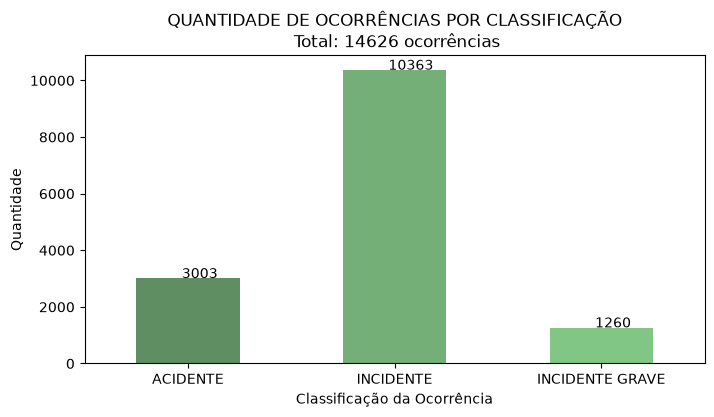

In [207]:
classe_ocorrencia = ocorrencia.groupby('Classificação')['Contagem'].sum().plot(kind='bar', figsize=(8,4), color=random.choice(colors), alpha=.7)

for p in classe_ocorrencia.patches:
    b=p.get_bbox()
    classe_ocorrencia.annotate("{:.0f}".format(b.y1 + b.y0), ((b.x0 + b.x1)/2 - 0.03, b.y1 + 15))

plt.xticks(rotation=0)
plt.xlabel('Classificação da Ocorrência')
plt.ylabel('Quantidade')
plt.title('QUANTIDADE DE OCORRÊNCIAS POR CLASSIFICAÇÃO\n Total: '+str(ocorrencia['Contagem'].sum())+' ocorrências')